# Mercury orbit Simulation

In this simulation, we want to solve the equations of motion for an N-body gravitational system, where each body interacts with every other body. (Newton's law of gravitation)

We need to solve a second-order differential equation:

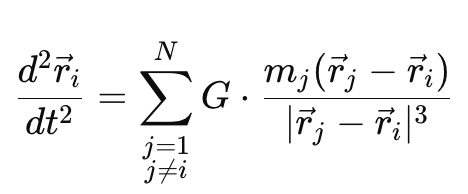

ri(t) is the position vector of body i, measured with respect to the Sun as the origin.

These equations form a coupled system of nonlinear ODEs, which has no analytical solution.
Therfore, we convert the system into first-order ODEs, and then use numerical integration methods to step forward in time.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from astropy.constants import G, M_sun
from astropy import units as u
from scipy.stats import linregress
from scipy.signal import argrelmin

In [14]:
AU = (1 * u.AU).to(u.m).value #Convert AU to m
year = (1 * u.yr).to(u.s).value #Convert year into s
G_val = G.value 
M_sun_val  = M_sun.value

In [15]:
# Defines a Body class that represents a celestial object in the simutlation.
# Each object created from this class stores "name", "mass", "position" and "velocity".
class Body:
    def __init__(self, name, mass, position, velocity): #__init__ is called automatically when a new object of the class is created
        self.name = name
        self.mass = mass
        self.position = np.array(position, dtype=np.float64) #Use float64 to ensure numerical stability during integration
        self.velocity = np.array(velocity, dtype=np.float64)

In [19]:
# Define a dictionary
planet_data = {
    "Sun": {
        "mass": M_sun_val
    },
    "Mercury": {
        "mass": 3.3011e23,
        "a": 0.38709893, # in AU
        "e": 0.205630
    },
    "Venus": {
        "mass": 4.867e24,
        "a": 0.72333199,
        "e": 0.006773
    },
    "Earth": {
        "mass": 5.972e24,
        "a": 1.00000011,
        "e": 0.016710
    },
    "Mars": {
        "mass": 6.417e23,
        "a": 1.52366231,
        "e": 0.093412
    },
    "Jupiter": {
        "mass": 1.898e27,
        "a": 5.20336301,
        "e": 0.048393
    },
    "Saturn": {
        "mass": 5.683e26,
        "a": 9.53707032,
        "e": 0.054150
    }
}

In [21]:
# Define a function preparing the full system that will be passed into the numerical integrator 
def build_system(include_planets):
    bodies = []
    bodies.append(Body("Sun", planet_data["Sun"]["mass"], [0, 0], [0, 0])) #The sun is always fixed at the origin
    
    for name in include_planets:
        pdata = planet_data[name]
        a = pdata["a"] * AU #Convert the unit of a from AU to m
        e = pdata["e"]
        r_peri = a * (1 - e)
        v_peri = np.sqrt(G_val * M_sun_val * (1 + e) / (a * (1 - e)))
        pos = [0, r_peri]
        vel = [v_peri, 0]
        bodies.append(Body(name, pdata["mass"], pos, vel))
    
    return bodies

Formula for the gravitational acceleration:

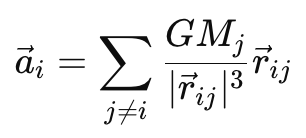

In [24]:
# Define a function that calculates the graviational acceleration acting on each body based on the current positions of all other bodies
def compute_accelerations(bodies):
    accels = [np.zeros(2) for _ in bodies] # Initialize acceleration as [0.0, 0.0]
# For every unique pair of different celestial bodies i ≠ j, the following loop calculates the gravitational acceleration that body b_j exerts on body b_i
    for i, bi in enumerate(bodies): # Use the function enumerate() to access each body and its corresponding index in the list of celestial bodies    
        for j, bj in enumerate(bodies):
            if i != j:
                r_vec = bj.position - bi.position # Calculate the displacement vector
                dist = np.linalg.norm(r_vec) # Calculate the distance 
                accels[i] += G_val * bj.mass * r_vec / dist**3
    return accels

In [26]:
# Define a function that converts the positions and velocities of all bodies into a flat 1D array
def flatten_state(bodies):
    state = []
    for body in bodies:
        state.extend(body.position) # .extend() adds each element of the given iterable to the end of the current list
        state.extend(body.velocity)
    return np.array(state) 

# Define a function that takes a 1D array and updates each body's position and velocity accordingly
def unflatten_state(state, bodies):
    for i, body in enumerate(bodies): 
        body.position = state[4*i:4*i+2] 
        # i is the corresponding index of the body, here, state[4*i:4*i+2] extracts two elements from the state array and assigns them to the body's position
        body.velocity = state[4*i+2:4*i+4]

# Function flatten_state(): Obtain a flat 1D array that can be passed into numerical integrators
# Function unflatten_state(): Take the result from numerical integration (a flat 1D array) and updates each body's position and velocity
# solve_ivp operate only on flat arrays, so we need to use these two functions to convert back and forth between object-oriented representation and flat 1D arrays

In [28]:
# Define a function that computes the time derivative of the system state at a specific time, which is designed to be passed into a numerical integrator (here we use solve_ivp).
# Time derivative of the system state --> the time derivative of each body's position is its current velocity, and the time derivative of its velocity is its current acceleration
def derivatives(t, state, bodies):
    unflatten_state(state, bodies)
    accels = compute_accelerations(bodies)
    derivs = []
    for i, body in enumerate(bodies):
        derivs.extend(body.velocity)
        derivs.extend(accels[i])
    return np.array(derivs)

In [30]:
# Define a function that finds each perihelion and computes its angular direction from the Sun
def compute_perihelion_angles(x, y):
    r = np.sqrt(x**2 + y**2)
    minima_indices = argrelmin(r)[0] # To find the indices of local minima 
    x_min = x[minima_indices]
    y_min = y[minima_indices]
    angles = np.arctan2(y_min, x_min)
    angles = np.unwrap(angles) # Ensures the angle progression is continuous
    return angles, minima_indices

In [32]:
# Define a function that calculates the average precession rate of Mercury's perihelion by fitting a line to the direction angles over time
def compute_precession_rate(angles, times):
    t_years = times / (365.25 * 24 * 3600)  
    slope_rad_per_year = linregress(t_years, angles).slope
    arcsec_per_century = np.degrees(slope_rad_per_year) * 3600 * 100
    return arcsec_per_century

In [34]:
# Define a function to run the N-body orbital simulation
def run_simulation(include_planets, total_years=100, steps=2000000):
    bodies = build_system(include_planets) #Calls the build_system() function to initialize all celestial bodies (Sun and selected planets) with mass, position, and velocity
    y0 = flatten_state(bodies) # Converts all positions and velocities of the bodies into a single 1D array to be used as the initial state for numerical integration
    t_span = (0, total_years * year) # Sets the simulation time span in seconds, from 0 to the total number of simulated years (converted to seconds)
    t_eval = np.linspace(*t_span, steps) # Creates an array of steps evenly spaced time points across the simulation time span
    sol = solve_ivp(derivatives, t_span, y0, t_eval=t_eval, args=(bodies,), rtol=1e-12, atol=1e-12, method='DOP853') #Uses solve_ivp to solve the system of ODEs
    
    names = [b.name for b in bodies]
    mercury_index = names.index("Mercury")
    # Extracts the positions of Mercury
    x = sol.y[4 * mercury_index, :] / AU
    y = sol.y[4 * mercury_index + 1, :] / AU
    angles, mask = compute_perihelion_angles(x, y)
    # angles contains the perihelion angles, mask contains the indices where these occur
    precession = compute_precession_rate(angles, sol.t[mask]) # sol.t --> the time points of the simulation
    
    return precession, x, y, sol.t

In [41]:
planet_sets = [
    ["Mercury"],
    ["Mercury","Jupiter"],
    ["Mercury","Jupiter", "Venus"],
    ["Mercury","Jupiter", "Venus", "Earth"],
    ["Mercury","Jupiter", "Venus", "Earth", "Saturn"],
    ["Mercury","Jupiter", "Venus", "Earth", "Saturn", "Mars"]
]

In [42]:
results = []
for planets in planet_sets:
    rate, _, _, _ = run_simulation(planets, total_years=100)
    results.append((planets, rate))

In [43]:
print("Precession contribution (arcsec/century):")
base = results[0][1] #Accesses the second element of the first tuple -- which is the precession rate
for planets, rate in results:
    print(f"{' + '.join(['Sun'] + planets):<45}: {rate:.2f}  (+{rate - base:.2f})") 

Precession contribution (arcsec/century):
Sun + Mercury                                : 683.54  (+0.00)
Sun + Mercury + Jupiter                      : 219659.04  (+218975.50)
Sun + Mercury + Jupiter + Venus              : 219507.61  (+218824.07)
Sun + Mercury + Jupiter + Venus + Earth      : 219364.34  (+218680.80)
Sun + Mercury + Jupiter + Venus + Earth + Saturn: 212302.89  (+211619.35)
Sun + Mercury + Jupiter + Venus + Earth + Saturn + Mars: 212213.51  (+211529.97)
